# Drug release from gelatin microspheres — Step 1: Fick (constant D) · Step 2: Fick + swelling (Abbasi-type)
**Saeedreza Barzkar — M.Sc. thesis modelling notebook (Sharif-style workflow)**

Run top-to-bottom in Google Colab (Runtime ▸ Run all). No uploads needed: the release data extracted
from the original papers are embedded below with their figure/page locators.

| Step | Model | What it assumes |
|---|---|---|
| 1 | Fick, constant D, perfect sink | drug only diffuses out of a sphere of fixed radius |
| 2 | Fick + swelling (Abbasi et al. 2008) | water diffuses in first; drug diffusivity rises with local water content: $D_d=D_{d,eq}\exp[-\beta_d(1-C_w/C_{w,eq})]$ |

Both models have **one fitted parameter** (a time scale) when the swelling constants are taken from Abbasi et al., so the comparison is fair.

In [1]:
# Imports and plot style
import numpy as np, pandas as pd, math, json, os
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from scipy.optimize import least_squares, brentq
from scipy.special import erfc
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 220, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6", "legend.frameon": False})
BLUE, ORANGE, GREEN, INK = "#2f5cf0", "#eb6834", "#1baf7a", "#3b3b3b"
OUT = "figures"; os.makedirs(OUT, exist_ok=True)

## 1. Release data extracted from gelatin-microsphere papers
Each point was taken from the paper itself: printed data labels, PDF vector coordinates, or
axis-calibrated digitization (cross-checked against numbers quoted in the text: 6 checks, max |difference| 0.63 %, five of six ≤ 0.15).
`R` = reference radius in µm (diameter/2) when the paper reports one; `unit='%'` means percent of the loaded drug.

In [2]:
# Embedded dataset
DATA = {
 "Morphine GMS": dict(ref="Jin et al., Des. Monomers Polym. 26 (2023) 1–14, Fig. 2, p. 7 (printed data row)",
    R=31.6, unit="%", amp_free=True,
    series={"MGM": ([0.0833,0.1667,0.5,0.75,1,1.5,2,4,8,12,24,36,48,60,72],
                    [0,5,12,21.5,25.8,37.2,40,47,55,56,57.1,57.5,58.1,58.5,59.2])}),
 "Diclofenac GMS": dict(ref="Saravanan et al., J. Drug Target. 19 (2011) 96–103, Fig. 6, p. 102 (vector-extracted)",
    R={"GM1 (9.8%)":18.9,"GM2 (18.3%)":20.3,"GM3 (26.7%)":22.7}, unit="%", amp_free=False,
    series={"GM1 (9.8%)": ([24,48,72,144,216,288,360,432,504,576,648,720],[9.98,15.04,20.02,25.0,30.99,35.98,41.03,45.02,48.01,51.01,53.99,55.99]),
            "GM2 (18.3%)": ([24,48,72,144,216,288,360,432,504,576,648,720],[16.05,26.01,32.0,38.05,45.03,51.02,57.0,63.05,68.03,72.03,76.01,80.0]),
            "GM3 (26.7%)": ([24,48,72,144,216,288,360,432,504,576,648,720],[25.0,35.98,44.02,52.0,58.98,66.03,73.02,78.0,81.98,84.98,88.04,91.03])}),
 "Ketoprofen GMS": dict(ref="Kodra et al., Polymers 18 (2026) 1807, Fig. 7c, p. 17 (digitized)",
    R=7.5, unit="%", amp_free=False,
    series={"MS/K-1 (4 h XL)": ([0.5,1,3,5,24],[12.9,17.4,34.0,35.6,62.3]),
            "MS/K-2 (2 h XL)": ([0.5,1,3,5,24],[10.6,22.3,41.9,84.8,100.0]),
            "MS/K-3 (0.5 h XL)": ([0.5,1,3,5,24],[9.0,37.1,99.6,99.8,100.0])}),
 "Vancomycin GMS": dict(ref="Zhang et al., Mater. Adv. 4 (2023) 4349–4368, Fig. 8B, p. 4362 (digitized; dialysis bag)",
    R=13.7, unit="%", amp_free=False,
    series={"pH 7.4": ([12,24,48,72,96,144,192,240,288,336],[25.41,37.24,45.89,52.33,56.16,59.62,62.18,63.92,65.11,66.52]),
            "pH 6.0": ([6,12,24,48,72,96,144,192,240,288,336],[21.46,29.63,40.97,52.37,60.07,65.99,70.61,74.10,75.97,77.17,78.01])}),
 "Gentamicin GMS (Chang)": dict(ref="Chang et al., Polymers 15 (2023) 1504, Fig. 5, p. 14 (digitized, mg/mL)",
    R={"1.0dM-G":10.5,"2.5dM-G":8.7}, unit="mg/mL", amp_free=True,
    series={"1.0dM-G": ([1,2,4,8,24,48,96,192,384,768],[2.46,3.82,3.94,3.96,3.99,3.97,3.96,3.95,4.03,4.79]),
            "2.5dM-G": ([1,2,4,8,24,48,96,192,384,768],[2.65,4.01,4.11,4.13,4.16,4.16,4.16,4.16,4.53,7.72])}),
 "Gentamicin m-EmG (Hu)": dict(ref="Hu et al., Materials 17 (2024) 3578, Fig. 5, p. 10 (digitized, net of drug-free background)",
    R=8.05, unit="mg", amp_free=True,
    series={"m-EmG net": ([1,2,4,8,24,48,96,192,288,384,480,576,672,768],
                          [0.106,0.172,0.233,0.284,0.297,0.314,0.338,0.358,0.350,0.350,0.362,0.371,0.285,0.305])}),
 "bFGF GMS": dict(ref="Lan et al., PLoS ONE 12 (2017) e0173814, Fig. 3, p. 9 (digitized)",
    R={"A porous":17.5,"B normal":None}, unit="%", amp_free=False,
    series={"A porous": ([10.1,24,48,72,119.8,167.5,215.5,288,359.8,480,696],[1.0,2.8,5.1,8.0,15.65,28.86,40.97,51.21,55.36,62.1,65.7]),
            "B normal": ([10.1,23.5,48,72,119.8,168,216,288,360,479.8,696],[3.36,6.88,30.6,45.1,64.8,82.38,91.43,94.7,95.3,96.22,97.07])}),
 "Icariin GMs": dict(ref="Liu et al., BioMed. Eng. OnLine 21 (2022) 89, Fig. 1A, p. 4 (digitized)",
    R=None, unit="%", amp_free=False,
    series={"GM-1 (0.25 mM)": ([24,72,168,240,336,504],[19.34,36.05,55.48,65.83,69.93,74.90]),
            "GM-2 (0.5 mM)": ([24,72,168,240,336,504],[32.10,57.17,69.77,79.94,88.23,94.72])}),
}
def radius(case, name):
    R = DATA[case]["R"]; return R.get(name) if isinstance(R, dict) else R

## 2. Step 1 — Fick's law in a sphere (constant D)
$$\frac{\partial C}{\partial t}=\frac{D}{r^2}\frac{\partial}{\partial r}\Big(r^2\frac{\partial C}{\partial r}\Big),\quad C(r,0)=C_0,\ \partial_rC(0,t)=0,\ C(R,t)=0$$
$$F(\tau)=1-\frac{6}{\pi^2}\sum_{n\ge1}\frac{e^{-n^2\pi^2\tau}}{n^2},\qquad \tau=\frac{Dt}{R^2}=k\,t$$
Creative detail: the series converges slowly at short times, so we switch to the exact short-time
(image) form below τ = 0.01 — both agree to 1e-13.

In [3]:
# Fick analytical solution
def fick_F(tau):
    tau = np.atleast_1d(np.asarray(tau, float)); out = np.zeros_like(tau)
    s = (tau > 0) & (tau < 0.01); l = tau >= 0.01
    t = tau[s]; z = np.arange(1, 7)[:, None] / np.sqrt(t)[None, :]
    ierfc = np.exp(-z**2) / np.sqrt(np.pi) - z * erfc(z)
    out[s] = 6 * np.sqrt(t) * (1 / np.sqrt(np.pi) + 2 * ierfc.sum(0)) - 3 * t
    n = np.arange(1, 40)[:, None]
    out[l] = 1 - 6 / np.pi**2 * np.sum(np.exp(-n**2 * np.pi**2 * tau[l][None, :]) / n**2, axis=0)
    return out

def fick_profile(x, tau, nterms=600):
    n = np.arange(1, nterms + 1)[:, None]; x = np.maximum(np.asarray(x, float), 1e-9)[None, :]
    return np.ravel(2 / (np.pi * x) * np.sum((-1.0)**(n + 1) / n * np.sin(n * np.pi * x) * np.exp(-n**2 * np.pi**2 * tau), 0))

## 3. Step 2 — Fick + swelling (Abbasi, Eslamian & Rousseau, *Drug Delivery* 15 (2008) 455–463)
Abbasi et al. solve **two** coupled Fick equations (water i=1, drug i=2) with Fujita-type diffusivities (their Eq. 3):
$$D_i=D_{i,eq}\exp\!\Big[-\beta_i\Big(1-\frac{C_1}{C_{1,eq}}\Big)\Big]$$
$C_i$ is a mass concentration in the matrix; at t = 0 the matrix is dry ($\bar C_1=0$, $\bar C_2=1$); at the surface
$\bar C_1=1$ (equilibrium water) and $\bar C_2=0$ (perfect sink). Swelling is ideal (volume additivity, Eq. 15),
which gives the moving radius (their Eq. 17 written for a sphere):
$$\Big(1-\frac{C_{1,eq}}{\rho_1}\Big)\frac{dR}{dt}=\frac{D_1}{\rho_1}\frac{\partial C_1}{\partial r}\Big|_R+\frac{D_2}{\rho_2}\frac{\partial C_2}{\partial r}\Big|_R$$
We solve it with the **front-fixing** variable $A=r/R(t)$ (as Abbasi did for the cylinder) and use their Table 1
constants for 5% gelatin / 0.1% caffeine: $D_{1,eq}=4.4\times10^{-5}$, $D_{2,eq}=3.8\times10^{-5}$ cm²/s, $\beta_1=6.8$, $\beta_2=8.5$.
Only the time scale $k_{eq}=D_{2,eq}/R_0^2$ is fitted to each microsphere curve.

In [4]:
# Coupled water–drug solver (sphere, front-fixing, backward Euler on a log time grid)
def simulate_swelling(tau_out, beta_w=6.8, beta_d=8.5, ratio=4.4/3.8, phi_w=0.0, phi_d=0.0,
                      theta0=0.0, N=80, nsteps=700, profiles_at=()):
    """Dimensionless: tau = D_d,eq t / R0^2, A = r/R(t), theta = C_w/C_w,eq, c = C_d/C_d0.
    phi_w = C_w,eq/rho_w (equilibrium water volume fraction): 0 -> no size change (D(C_w) effect only)."""
    tau_out = np.asarray(tau_out, float)
    f = 1 - (1 - np.linspace(0, 1, N + 1))**1.8              # cells clustered near the surface (thin water front)
    V = (f[1:]**3 - f[:-1]**3) / 3; xc = 0.5 * (f[1:] + f[:-1])
    h = np.empty(N); h[:-1] = xc[1:] - xc[:-1]; h[-1] = 1 - xc[-1]          # distance to east neighbour
    Af = f**2; dfac = np.empty(N + 1); dfac[1:-1] = xc[1:] - xc[:-1]; dfac[-1] = 1 - xc[-1]; dfac[0] = 1
    grid = np.unique(np.concatenate([np.logspace(-7, np.log10(tau_out.max()), nsteps), tau_out]))
    th = np.full(N, theta0); c = np.ones(N); rho = 1.0; M0 = V.sum(); released = 0.0
    res = dict(tau=[], F=[], F_flux=[], R=[], water=[], prof={})
    done = np.zeros(len(tau_out), bool)
    t_prev = 0.0; rho_eq3 = 1 / (1 - phi_w) if phi_w > 0 else 1.0
    def implicit(u, Dface, a, dt, rhoN, ub):
        G = Af * Dface / dfac / rhoN**2; G[0] = 0.0
        main = V / dt + G[:-1] + G[1:] + V * a / h
        up = -G[1:-1] - (V * a / h)[:-1]
        lo = -G[1:-1]
        ab = np.zeros((3, N)); ab[0, 1:] = up; ab[1] = main; ab[2, :-1] = lo
        rhs = V * u / dt; rhs[-1] += (G[-1] + V[-1] * a[-1] / h[-1]) * ub
        return solve_banded((1, 1), ab, rhs), G
    for t in grid:
        dt = t - t_prev
        if dt > 0:
            gth = (1 - th[-1]) / h[-1]; gc = (0 - c[-1]) / h[-1]
            rhodot = (phi_w * ratio * gth + phi_d * gc) / (rho * (1 - phi_w)) if phi_w > 0 else 0.0
            rhoN = rho + dt * rhodot; a = xc * rhodot / rhoN
            thn = th.copy()
            for _ in range(2):                                   # Picard sweeps for the nonlinear water equation
                thf = np.empty(N + 1); thf[1:-1] = 0.5 * (thn[1:] + thn[:-1]); thf[0] = thn[0]; thf[-1] = 1.0
                thn, _G = implicit(th, ratio * np.exp(-beta_w * (1 - thf)), a, dt, rhoN, 1.0)
            th = np.clip(thn, 0, 1)
            if phi_w > 0:                                        # volume-additivity closure (exact Eq. 15)
                rhoN = (1.0 / (1.0 - phi_w * np.dot(V, th) / M0)) ** (1 / 3)
                a = xc * (rhoN - rho) / dt / rhoN
            thf = np.empty(N + 1); thf[1:-1] = 0.5 * (th[1:] + th[:-1]); thf[0] = th[0]; thf[-1] = 1.0
            c, Gd = implicit(c, np.exp(-beta_d * (1 - thf)), a, dt, rhoN, 0.0)
            released += dt * Gd[-1] * c[-1] * rhoN**3 / M0      # outlet flux, scaled to the current size
            rho = rhoN; t_prev = t
        hit = np.where(np.isclose(tau_out, t, rtol=1e-12, atol=0) & ~done)[0]
        for j in hit:
            done[j] = True
            res["tau"].append(t); res["F"].append(1 - rho**3 * np.dot(V, c) / M0); res["F_flux"].append(released)
            res["R"].append(rho); res["water"].append(rho**3 * np.dot(V, th) / (M0 * rho_eq3))
            if j in profiles_at: res["prof"][j] = (xc * rho, th.copy(), c.copy())
    return {k: (np.array(v) if k != "prof" else v) for k, v in res.items()}

### Verification of the swelling solver (no data involved)
1. With β = 0 and no size change it must reproduce the Fick series. 2. Drug lost from the sphere must equal the integrated outlet flux.
3. With size change, the final radius must obey volume additivity: $(R_{eq}/R_0)^3=1/(1-\phi_w)$.

In [5]:
# Verification
tv = np.array([0.003, 0.01, 0.03, 0.1, 0.3])
v0 = simulate_swelling(tv, beta_w=0, beta_d=0, N=120, nsteps=1500)
print("beta=0 vs Fick series, max |dF| =", np.abs(v0["F"] - fick_F(tv)).max())
v1 = simulate_swelling(np.array([0.1, 1, 10, 60]), phi_w=0.0)
print("mass balance (fixed size), max |F_inventory - F_flux| =", np.abs(v1["F"] - v1["F_flux"]).max())
v2 = simulate_swelling(np.array([1, 10, 100, 400]), phi_w=0.8, nsteps=1500)
print("final (R/R0)^3 =", v2["R"][-1]**3, " expected 1/(1-phi) =", 1 / (1 - 0.8), "| water uptake:", v2["water"].round(3))
print("mass balance (with size change), max |F_inventory - F_flux| =", np.abs(v2["F"] - v2["F_flux"]).max())

beta=0 vs Fick series, max |dF| = 0.0006924723868666494
mass balance (fixed size), max |F_inventory - F_flux| = 2.220446049250313e-16


final (R/R0)^3 = 5.000000000000001  expected 1/(1-phi) = 5.000000000000001 | water uptake: [0.814 1.    1.    1.   ]
mass balance (with size change), max |F_inventory - F_flux| = 0.008770539343586181


## 4. Master curves and fitting
For fixed swelling constants the release curve is a single dimensionless shape $F_{sw}(\tau)$; fitting a microsphere
curve only stretches it in time ($\tau = k\,t$). We pre-compute the shape once and fit by interpolation — fast enough for Colab.

In [6]:
# Master curves
TAU = np.logspace(-6, np.log10(400), 500)
MASTER = {"fick": fick_F(TAU)}
MASTER["swell"] = simulate_swelling(TAU)["F"]                         # Abbasi constants, rigid size (phi_w = 0)
# Kodra 2026 measured peak swelling SD% of the SAME formulations (Fig. 7a, p. 17; text: 1942 % for MS/K-1):
# water/polymer mass q = SD/100 -> equilibrium water volume fraction phi_w = q / (q + rho_w/rho_gelatin), rho_gelatin ~ 1.35 g/cm3
SD_PEAK = {"MS/K-1 (4 h XL)": 1942, "MS/K-2 (2 h XL)": 1701, "MS/K-3 (0.5 h XL)": 930}
PHI = {k: (v / 100) / (v / 100 + 1 / 1.35) for k, v in SD_PEAK.items()}
MASTER_SIZE = {k: simulate_swelling(TAU, phi_w=p, nsteps=1500)["F"] for k, p in PHI.items()}   # + moving boundary (dry R0 = 7.5 um)
print("phi_w used for size change:", {k: round(v, 3) for k, v in PHI.items()})
BETAS = np.arange(0, 12.5, 1.0)
MASTER_B = np.array([simulate_swelling(TAU, beta_d=b)["F"] for b in BETAS])   # sensitivity to beta_d
def interp_curve(curve, tau):
    tau = np.clip(np.asarray(tau, float), TAU[0], TAU[-1])
    return np.interp(np.log(tau), np.log(TAU), curve)
def model(kind, t, k, A=1.0, name=None):
    t = np.asarray(t, float)
    curve = MASTER_SIZE[name] if kind == "size" else MASTER[kind]
    y = interp_curve(curve, k * t)
    return A * np.where(t > 0, y, 0.0)

def fit(kind, t, y, amp_free, name=None):
    best = None
    for lk in np.arange(-9, 3, 0.5):
        x0 = [lk] + ([math.log(max(y.max(), 1e-9))] if amp_free else [])
        f = lambda v: model(kind, t, math.exp(v[0]), math.exp(v[1]) if amp_free else 1.0, name) - y
        r = least_squares(f, x0)
        if best is None or r.cost < best.cost: best = r
    k = math.exp(best.x[0]); A = math.exp(best.x[1]) if amp_free else 1.0
    J = best.jac; dof = len(t) - len(best.x)
    se_k = (k * math.sqrt(np.linalg.pinv(J.T @ J)[0, 0] * 2 * best.cost / dof)) if dof > 0 else np.nan
    return k, A, se_k

def split_n(n):  # fixed temporal split: first max(3, floor(0.6 n)) points train
    ntr = max(3, int(0.6 * n)); return min(ntr, n - 2)

rows = []
for case, d in DATA.items():
    for name, (t, y) in d["series"].items():
        t = np.array(t, float); y = np.array(y, float) / (100 if d["unit"] == "%" else 1)
        ntr = split_n(len(t)); scale = 100 if d["unit"] == "%" else 1
        for kind in (["fick", "swell", "size"] if case.startswith("Keto") else ["fick", "swell"]):
            k, A, se = fit(kind, t, y, d["amp_free"], name)
            kt, At, _ = fit(kind, t[:ntr], y[:ntr], d["amp_free"], name)
            res = y - model(kind, t, k, A, name); pred = model(kind, t, kt, At, name)
            R = radius(case, name)
            rows.append(dict(case=case, formulation=name, model={"fick": "Fick (const D)", "swell": "Fick + swelling", "size": "Fick + swelling + size change"}[kind],
                             k_per_h=k, k_se=se, A=A, RMSE=np.sqrt(np.mean(res**2)) * scale,
                             test_RMSE=np.sqrt(np.mean((y[ntr:] - pred[ntr:])**2)) * scale,
                             D_cm2_s=(k / 3600 * (R * 1e-4)**2 if R else np.nan), n=len(t), n_train=ntr))
RES = pd.DataFrame(rows)
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print(RES[["case", "formulation", "model", "k_per_h", "A", "RMSE", "test_RMSE", "D_cm2_s"]].to_string(index=False))
RES.to_csv("fit_results.csv", index=False)

phi_w used for size change: {'MS/K-1 (4 h XL)': 0.963, 'MS/K-2 (2 h XL)': 0.958, 'MS/K-3 (0.5 h XL)': 0.926}


                  case       formulation                         model   k_per_h      A    RMSE  test_RMSE   D_cm2_s
          Morphine GMS               MGM                Fick (const D)   0.02457 0.5849   4.113       12.3 6.815e-11
          Morphine GMS               MGM               Fick + swelling    0.1078 0.5789    3.91      4.294 2.991e-10
        Diclofenac GMS        GM1 (9.8%)                Fick (const D) 5.325e-05      1   1.313      2.757 5.284e-14
        Diclofenac GMS        GM1 (9.8%)               Fick + swelling 0.0002367      1    1.01      1.983 2.349e-13
        Diclofenac GMS       GM2 (18.3%)                Fick (const D) 0.0001309      1   2.522      4.739 1.498e-13
        Diclofenac GMS       GM2 (18.3%)               Fick + swelling 0.0005568      1   2.085      3.209 6.374e-13
        Diclofenac GMS       GM3 (26.7%)                Fick (const D) 0.0002444      1   2.034      1.129 3.498e-13
        Diclofenac GMS       GM3 (26.7%)               Fick + sw

## 5. The "whiteboard" figure
**(a) theory** — the three models on one time axis with the *same* equilibrium diffusivity;
**(b) data** — every extracted curve, time divided by its own $t_{50}$ so only the shape remains, coloured by behaviour:
Fick-like · delayed / S-shaped (swelling-like) · plateau below 100 % ("curve 2") · late second rise ("curve 1", degradation).

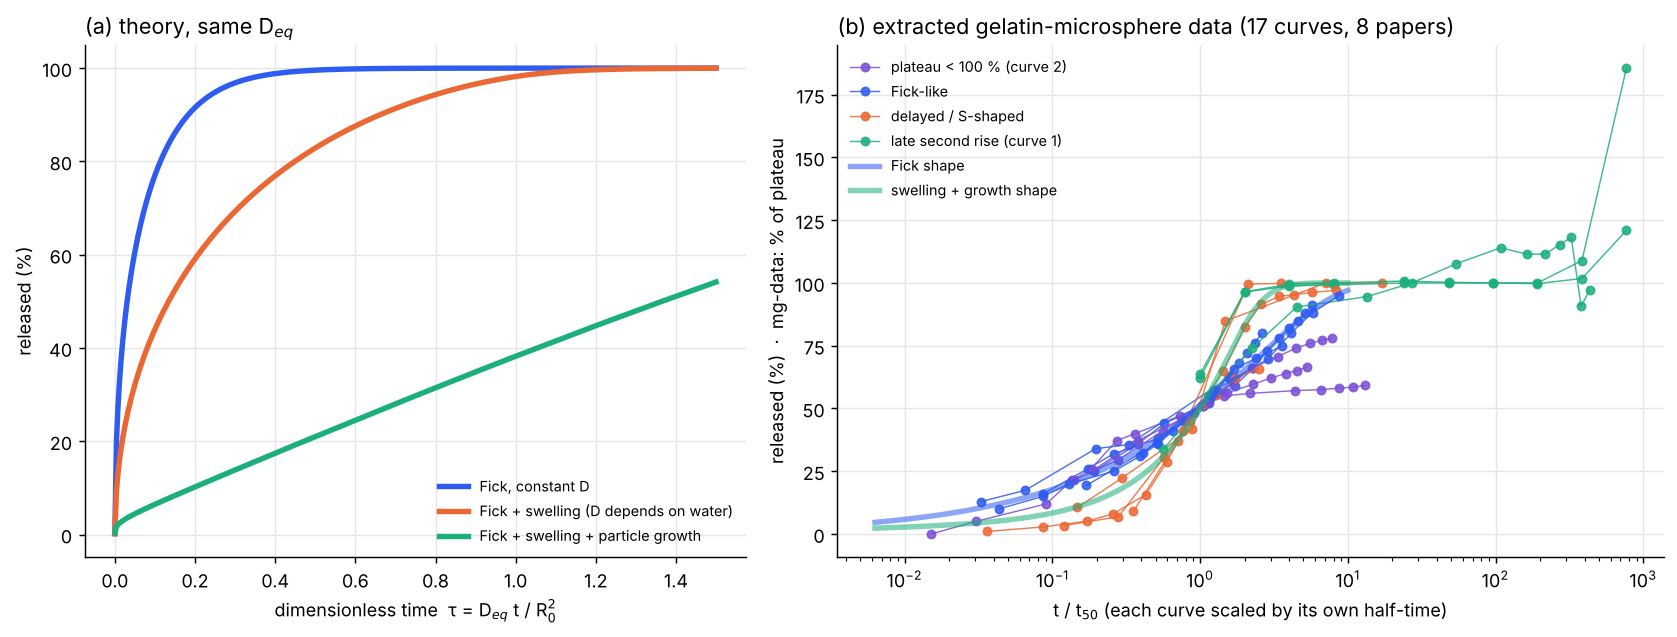

In [7]:
# Whiteboard figure
def t_half(t, y):
    i = int(np.argmax(y >= 0.5)); return np.interp(0.5, [y[i - 1], y[i]], [t[i - 1], t[i]]) if i > 0 else t[0]
GROUP = {"Fick-like": ["GM1 (9.8%)", "GM2 (18.3%)", "GM3 (26.7%)", "GM-1 (0.25 mM)", "GM-2 (0.5 mM)", "MS/K-1 (4 h XL)"],
         "delayed / S-shaped": ["A porous", "B normal", "MS/K-2 (2 h XL)", "MS/K-3 (0.5 h XL)"],
         "plateau < 100 % (curve 2)": ["pH 7.4", "pH 6.0", "MGM"],
         "late second rise (curve 1)": ["2.5dM-G", "1.0dM-G", "m-EmG net"]}
GCOL = {"Fick-like": BLUE, "delayed / S-shaped": ORANGE, "plateau < 100 % (curve 2)": "#7b4fd6", "late second rise (curve 1)": GREEN}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw=dict(width_ratios=[1, 1.25]))
tl = np.linspace(0, 1.5, 400)
ax[0].plot(tl, interp_curve(MASTER["fick"], tl) * 100, color=BLUE, lw=3, label="Fick, constant D")
ax[0].plot(tl, interp_curve(MASTER["swell"], tl) * 100, color=ORANGE, lw=3, label="Fick + swelling (D depends on water)")
ax[0].plot(tl, interp_curve(MASTER_SIZE["MS/K-1 (4 h XL)"], tl) * 100, color=GREEN, lw=3, label="Fick + swelling + particle growth")
ax[0].set_xlabel("dimensionless time  τ = D$_{eq}$ t / R$_0^2$"); ax[0].set_ylabel("released (%)"); ax[0].legend(fontsize=8, loc="lower right")
ax[0].set_title("(a) theory, same D$_{eq}$", loc="left")
seen = set()
for case, d in DATA.items():
    for name, (t, y) in d["series"].items():
        t = np.array(t, float); y = np.array(y, float)
        yn = y / 100 if d["unit"] == "%" else y / np.median(y[(t >= 8) & (t <= 192)])
        g = [k for k, v in GROUP.items() if name in v][0]
        ax[1].plot(t / t_half(t, yn), yn * 100, "o-", color=GCOL[g], ms=4.5, lw=0.8, alpha=0.85, label=g if g not in seen else None)
        seen.add(g)
x = np.logspace(-2.2, 1.0, 300)
for key, col, lab in [("fick", BLUE, "Fick shape"), ("size", GREEN, "swelling + growth shape")]:
    curve = MASTER["fick"] if key == "fick" else MASTER_SIZE["MS/K-2 (2 h XL)"]
    h50 = brentq(lambda s_: interp_curve(curve, s_) - 0.5, 1e-6, 300)
    ax[1].plot(x, interp_curve(curve, x * h50) * 100, color=col, lw=3, alpha=0.55, label=lab)
ax[1].set_xscale("log"); ax[1].set_xlabel("t / t$_{50}$ (each curve scaled by its own half-time)")
ax[1].set_ylabel("released (%)  ·  mg-data: % of plateau"); ax[1].legend(fontsize=8, loc="upper left")
ax[1].set_title("(b) extracted gelatin-microsphere data (17 curves, 8 papers)", loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/whiteboard_master.png"); plt.show()

## 6. Side-by-side: data, Fick (constant D), Fick + swelling — per case

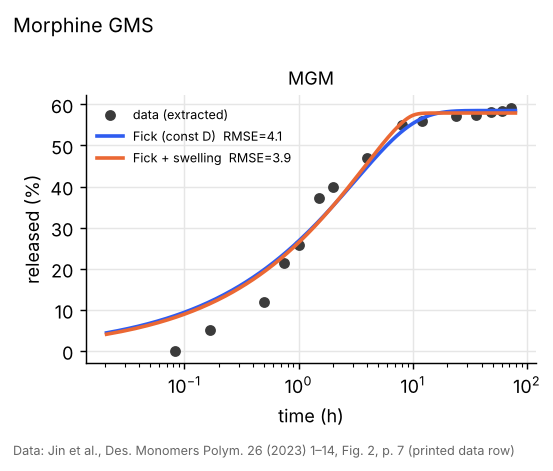

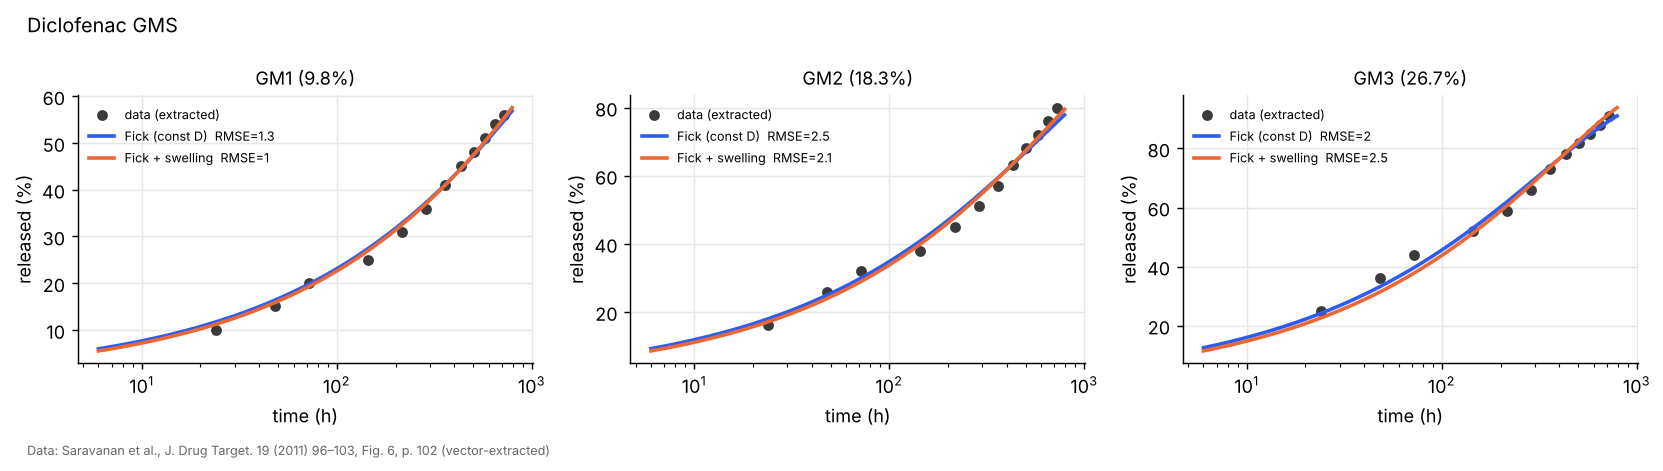

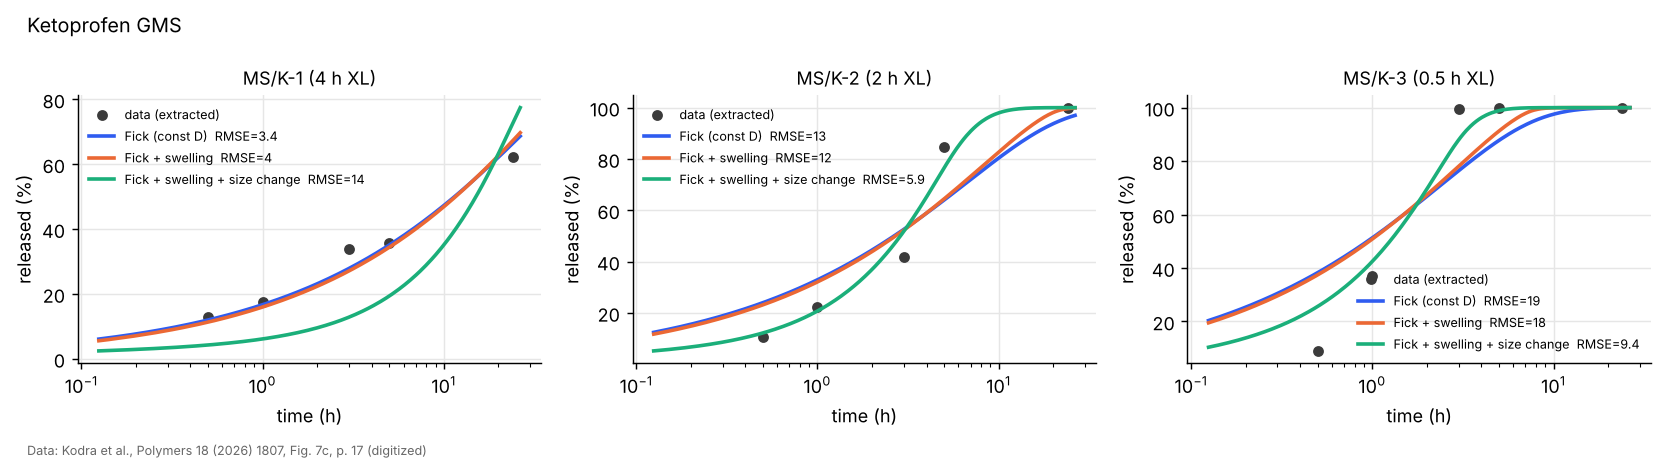

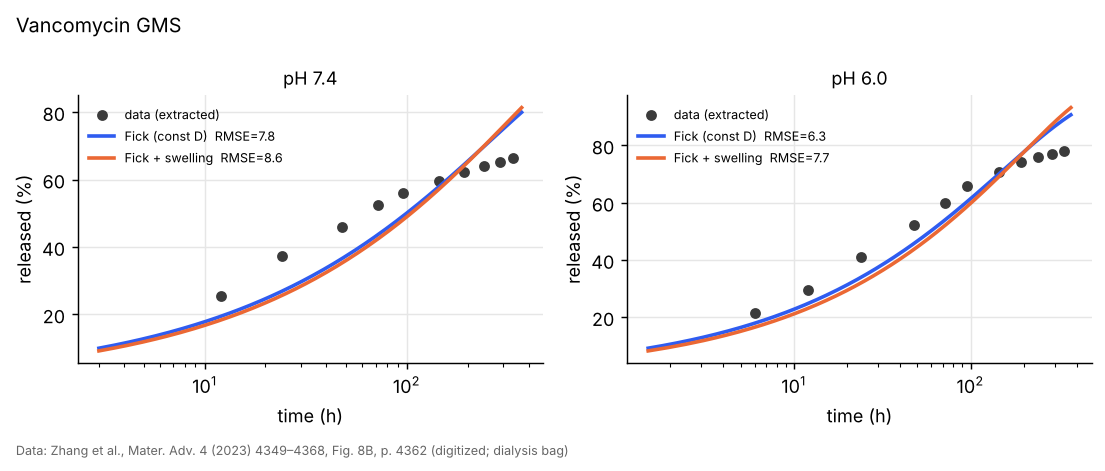

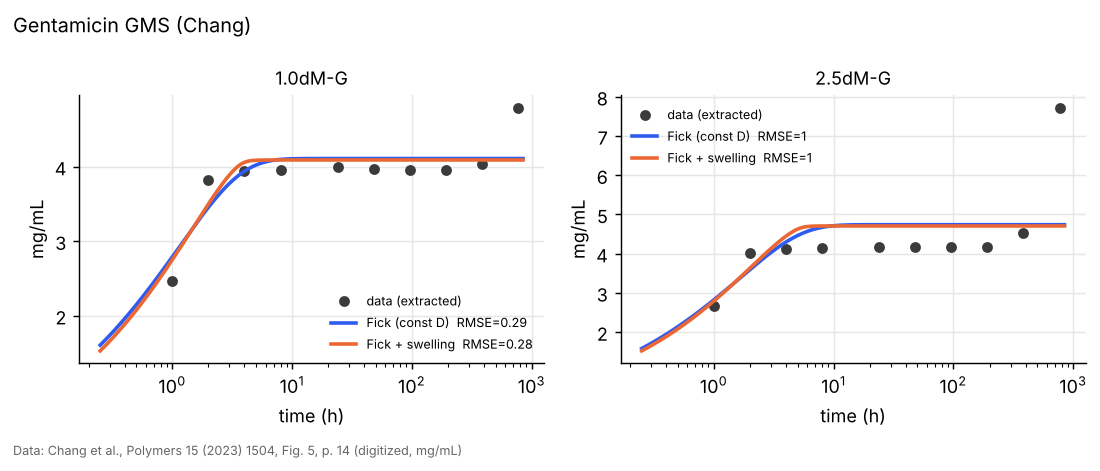

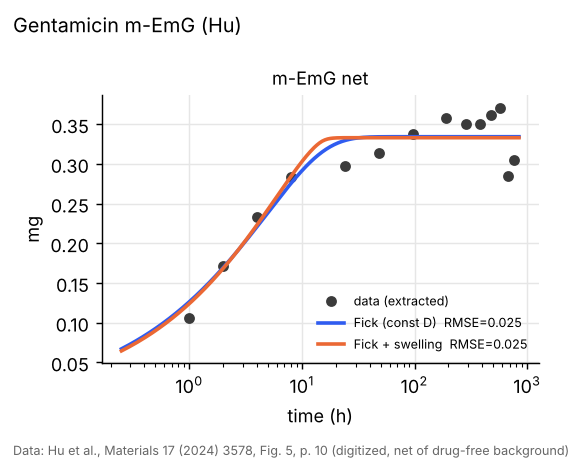

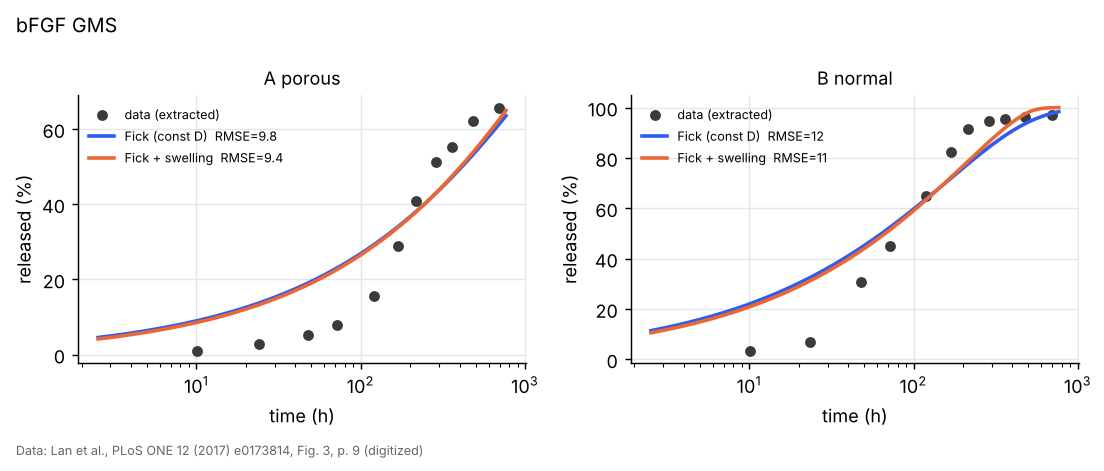

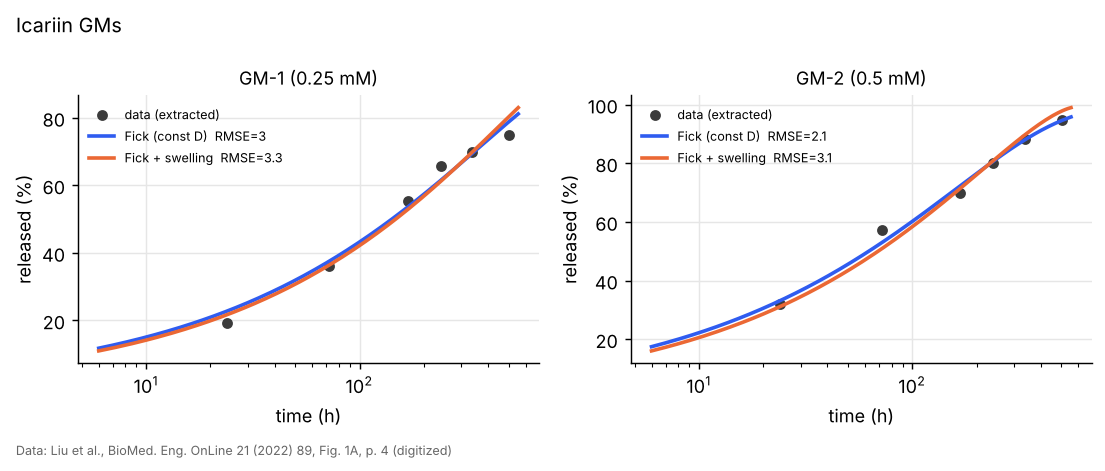

In [8]:
# Per-case figures
for case, d in DATA.items():
    names = list(d["series"]); fig, axs = plt.subplots(1, len(names), figsize=(4.3 * len(names), 3.4), squeeze=False)
    for ax, name in zip(axs[0], names):
        t, y = map(lambda a: np.array(a, float), d["series"][name]); s = 100 if d["unit"] == "%" else 1
        tt = np.logspace(np.log10(t.min() / 4), np.log10(t.max() * 1.1), 300)
        ax.plot(t, y, "o", color=INK, ms=5, label="data (extracted)")
        LAB = {"fick": "Fick (const D)", "swell": "Fick + swelling", "size": "Fick + swelling + size change"}
        for kind, col in [("fick", BLUE), ("swell", ORANGE), ("size", GREEN)]:
            sel = RES[(RES.case == case) & (RES.formulation == name) & (RES.model == LAB[kind])]
            if not len(sel): continue
            r = sel.iloc[0]
            ax.plot(tt, model(kind, tt, r.k_per_h, r.A, name) * s, color=col, lw=2, label=f"{LAB[kind]}  RMSE={r.RMSE:.2g}")
        ax.set_xscale("log"); ax.set_title(name, fontsize=10); ax.set_xlabel("time (h)")
        ax.set_ylabel("released (%)" if d["unit"] == "%" else d["unit"]); ax.legend(fontsize=7)
    fig.suptitle(case, x=0.02, ha="left", fontsize=11); fig.text(0.02, -0.02, "Data: " + d["ref"], fontsize=7, color="#666")
    plt.tight_layout(); plt.savefig(f"{OUT}/case_{case.split()[0].lower()}_{len(names)}.png", bbox_inches="tight"); plt.show()

## 7. What swelling does inside the particle (water front and drug profile)

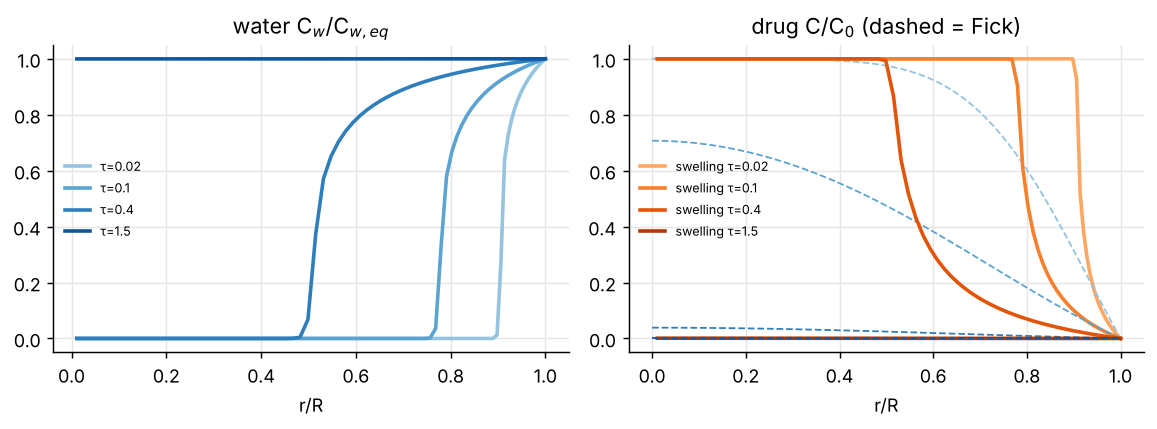

In [9]:
# Internal profiles
tp = np.array([0.02, 0.1, 0.4, 1.5]); sim = simulate_swelling(tp, profiles_at=range(4))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for i, t in enumerate(tp):
    r, th, c = sim["prof"][i]
    ax[0].plot(r, th, color=plt.cm.Blues(0.4 + 0.15 * i), lw=2, label=f"τ={t}")
    ax[1].plot(r, c, color=plt.cm.Oranges(0.4 + 0.15 * i), lw=2, label=f"swelling τ={t}")
    ax[1].plot(np.linspace(0, 1, 100), fick_profile(np.linspace(0, 1, 100), t), "--", color=plt.cm.Blues(0.4 + 0.15 * i), lw=1)
ax[0].set_title("water C$_w$/C$_{w,eq}$"); ax[1].set_title("drug C/C$_0$ (dashed = Fick)")
for a in ax: a.set_xlabel("r/R"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/profiles_swelling.png"); plt.show()

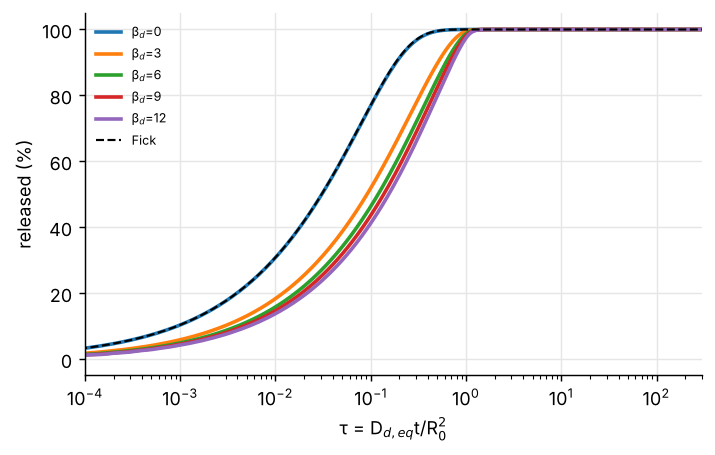

Done. Figures in ./figures, table in fit_results.csv


In [10]:
# Sensitivity to beta_d (how strongly D depends on water)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for b, curve in zip(BETAS[::3], MASTER_B[::3]):
    ax.plot(TAU, curve * 100, lw=2, label=f"β$_d$={b:g}")
ax.plot(TAU, MASTER["fick"] * 100, "k--", lw=1.2, label="Fick")
ax.set_xscale("log"); ax.set_xlim(1e-4, 300); ax.set_xlabel("τ = D$_{d,eq}$t/R$_0^2$"); ax.set_ylabel("released (%)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/beta_sensitivity.png"); plt.show()
print("Done. Figures in ./figures, table in fit_results.csv")